# 01 : Data Exploration and Cleaning

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [4]:
DATA_DIR = "../data/PetImages"
CLASSES = ["Cat", "Dog"]

for label in CLASSES:
    folder = os.path.join(DATA_DIR, label)
    print(folder, "exists:", os.path.isdir(folder))

../data/PetImages/Cat exists: True
../data/PetImages/Dog exists: True


## 1. Counting number of images in each class

In [5]:
rows = []

for label in CLASSES:
    folder = os.path.join(DATA_DIR, label)
    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)
        rows.append({"filepath": filepath, "label": label})

df = pd.DataFrame(rows)

print("Total files:", len(df))
print(df["label"].value_counts())
df.head()

Total files: 24998
label
Cat    12499
Dog    12499
Name: count, dtype: int64


,filepath,label
0,../data/PetImages/Cat/9733.jpg,Cat
1,../data/PetImages/Cat/63.jpg,Cat
2,../data/PetImages/Cat/6400.jpg,Cat
3,../data/PetImages/Cat/823.jpg,Cat
4,../data/PetImages/Cat/4217.jpg,Cat


## 2. Remove broken files

In [8]:
import warnings
warnings.filterwarnings("ignore")

def is_valid_image(filepath):
    try:
        with Image.open(filepath) as img:
            img.load()
            return img.format == "JPEG"
    except Exception:
        return False

df["is_good"] = df["filepath"].apply(is_valid_image)

bad_files = df[df["is_good"] == False]
print("Broken files:", len(bad_files))
print(bad_files["filepath"].tolist())

Broken files: 229
['../data/PetImages/Cat/1151.jpg', '../data/PetImages/Cat/1757.jpg', '../data/PetImages/Cat/3197.jpg', '../data/PetImages/Cat/7642.jpg', '../data/PetImages/Cat/4821.jpg', '../data/PetImages/Cat/4000.jpg', '../data/PetImages/Cat/10874.jpg', '../data/PetImages/Cat/11565.jpg', '../data/PetImages/Cat/1386.jpg', '../data/PetImages/Cat/10125.jpg', '../data/PetImages/Cat/8832.jpg', '../data/PetImages/Cat/3967.jpg', '../data/PetImages/Cat/6980.jpg', '../data/PetImages/Cat/4629.jpg', '../data/PetImages/Cat/4833.jpg', '../data/PetImages/Cat/3153.jpg', '../data/PetImages/Cat/12269.jpg', '../data/PetImages/Cat/2663.jpg', '../data/PetImages/Cat/11210.jpg', '../data/PetImages/Cat/12080.jpg', '../data/PetImages/Cat/6029.jpg', '../data/PetImages/Cat/7647.jpg', '../data/PetImages/Cat/6376.jpg', '../data/PetImages/Cat/8415.jpg', '../data/PetImages/Cat/9778.jpg', '../data/PetImages/Cat/11935.jpg', '../data/PetImages/Cat/9208.jpg', '../data/PetImages/Cat/3491.jpg', '../data/PetImages/Cat

In [9]:
def investigate_bad_files(filepath):
    try:
        with Image.open(filepath) as img:
            img.load()
            return "not a JPEG (" + str(img.format) + ")"
    except Exception:
        return "cannot open"

bad_files = bad_files.copy()
bad_files["problem"] = bad_files["filepath"].apply(investigate_bad_files)

print(bad_files["label"].value_counts())
print()
print(bad_files["problem"].value_counts())

label
Dog    135
Cat     94
Name: count, dtype: int64

problem
not a JPEG (BMP)    173
not a JPEG (GIF)     51
not a JPEG (PNG)      4
not a JPEG (PSD)      1
Name: count, dtype: int64


In [10]:
df = df[df["is_good"]].drop(columns="is_good").reset_index(drop=True)

print("Usable images:", len(df))
print(df["label"].value_counts())

Usable images: 24769
label
Cat    12405
Dog    12364
Name: count, dtype: int64


## 3. Image sizes and color modes

In [11]:
widths = []
heights = []
modes = []

for filepath in df["filepath"]:
    with Image.open(filepath) as img:
        widths.append(img.width)
        heights.append(img.height)
        modes.append(img.mode)

df["width"] = widths
df["height"] = heights
df["mode"] = modes

print(df[["width", "height"]].describe().round(1))
print()
print(df["mode"].value_counts())

         width   height
count  24769.0  24769.0
mean     405.6    361.9
std      108.2     96.4
min        4.0      4.0
25%      326.0    304.0
50%      448.0    375.0
75%      500.0    422.0
max      500.0    500.0

mode
RGB     24761
L           5
CMYK        3
Name: count, dtype: int64


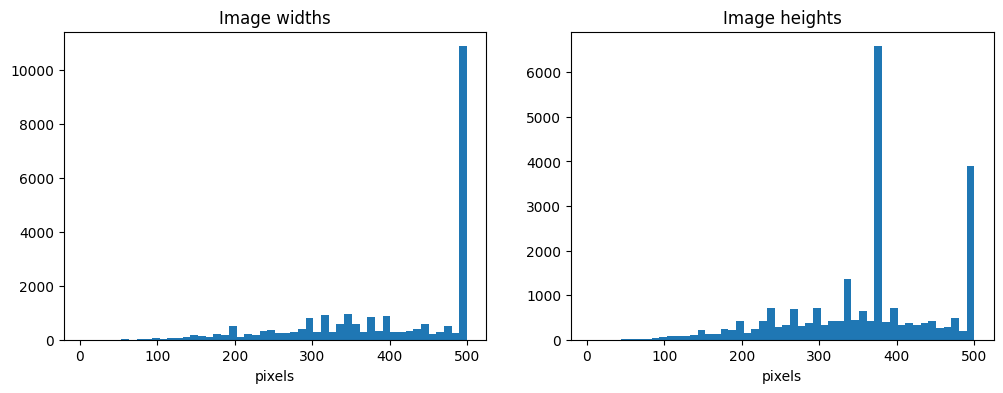

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["width"], bins=50)
axes[0].set_title("Image widths")
axes[0].set_xlabel("pixels")

axes[1].hist(df["height"], bins=50)
axes[1].set_title("Image heights")
axes[1].set_xlabel("pixels")

plt.show()

In [13]:
small = df[(df["width"] < 50) | (df["height"] < 50)]

print("Images smaller than 50 pixels on either side:", len(small))
print(small[["filepath", "label", "width", "height"]])

Images smaller than 50 pixels on either side: 10
                              filepath label  width  height
1328    ../data/PetImages/Cat/5527.jpg   Cat     60      45
1546    ../data/PetImages/Cat/6402.jpg   Cat     60      33
2558    ../data/PetImages/Cat/5534.jpg   Cat     60      36
6869    ../data/PetImages/Cat/2433.jpg   Cat     60      41
10039   ../data/PetImages/Cat/5673.jpg   Cat      4       4
14891   ../data/PetImages/Dog/9246.jpg   Dog     65      47
15579   ../data/PetImages/Dog/1324.jpg   Dog     60      45
16967  ../data/PetImages/Dog/11248.jpg   Dog    100      37
19755  ../data/PetImages/Dog/11686.jpg   Dog     60      48
22453   ../data/PetImages/Dog/9705.jpg   Dog     60      39


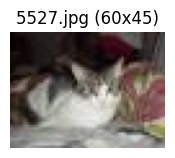

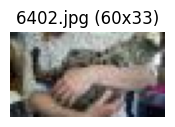

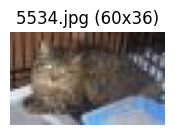

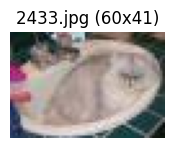

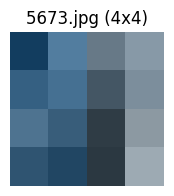

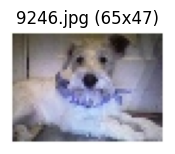

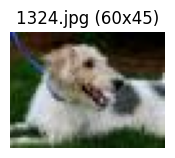

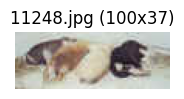

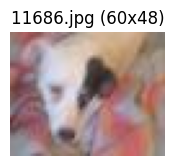

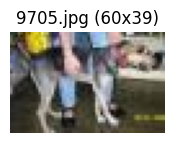

In [14]:
for filepath in small["filepath"]:
    img = Image.open(filepath).convert("RGB")
    plt.figure(figsize=(2,2))
    plt.imshow(img)
    plt.title(filepath.split("/")[-1] + f" ({img.width}x{img.height})")
    plt.axis("off")
    plt.show()

In [15]:
df = df[(df["width"] >= 10) & (df["height"] >= 10)].reset_index(drop=True)
print("Usable images:", len(df))
print(df["label"].value_counts())

Usable images: 24768
label
Cat    12404
Dog    12364
Name: count, dtype: int64


## 4. Example Images

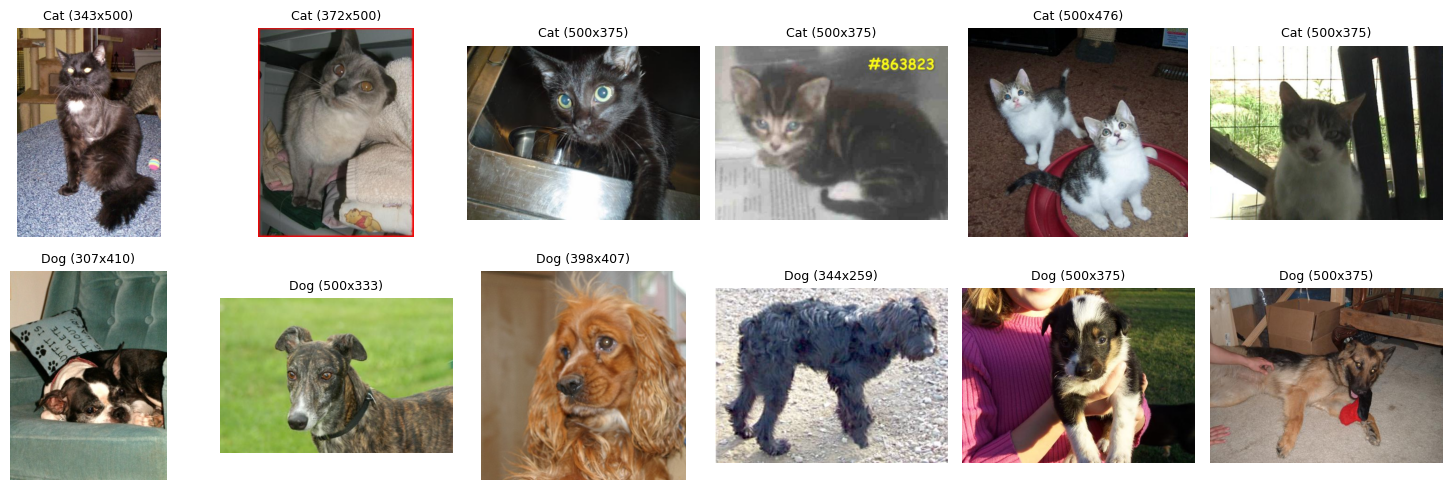

In [16]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for row, label in enumerate(CLASSES):
    examples = df[df["label"] == label].sample(6, random_state=42)
    for col, filepath in enumerate(examples["filepath"]):
        img = Image.open(filepath).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{label} ({img.width}x{img.height})", fontsize=9)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## 5. Train / Validation / Test Split (70/15/15)

In [17]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=42)

train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")

splits = pd.concat([train_df, val_df, test_df])
print(pd.crosstab(splits["split"], splits["label"], margins=True))

label    Cat    Dog    All
split                     
test    1861   1855   3716
train   8682   8655  17337
val     1861   1854   3715
All    12404  12364  24768


In [18]:
splits[["filepath", "label", "split"]].to_csv("../data/splits.csv", index=False)
print("Saved", len(splits), "rows to ../data/splits.csv")

Saved 24768 rows to ../data/splits.csv


## Summary

- **Dataset:** 24,998 images (12,499 cats, 12,499 dogs), so the classes are balanced and accuracy is a fair metric.
- **Cleaning:**
  - 229 files were named `.jpg` but were actually other formats (173 BMP, 51 GIF, 4 PNG, 1 PSD). We removed them to keep a consistent input format.
  - One 4×4 image with no animal in it was also removed.
  - Small but recognizable images (around 60×45) were kept.
- **Final dataset:** 24,768 images (12,404 cats, 12,364 dogs).
- **Image sizes** vary from tiny up to 500×500 pixels, so every image must be resized to a fixed size before training.
- **Color modes:** 8 images are grayscale or CMYK, so all images are converted to one color mode when loaded.
- **Split:** stratified 70/15/15 → 17,337 train / 3,715 validation / 3,716 test, saved to `data/splits.csv` so every model uses the same split.